# 1. Introducción del Proyecto: Predicción de la Diabetes

### Objetivo
El objetivo de este proyecto es construir un modelo de regresión para predecir la progresión de la enfermedad de diabetes en los pacientes con un año de diferencia respecto a la línea de base, basándose en varias características numéricas como la edad, el IMC y la presión arterial.

### Tipo de Problema
Este es un problema de **regresión**, ya que estamos prediciendo una medida cuantitativa continua de la progresión de la enfermedad.

### Punto de Partida Exploratorio
Este cuaderno representa la fase exploratoria inicial del flujo de trabajo de un científico de datos. El foco aquí está en comprender los datos, validar su calidad, realizar una limpieza básica y probar modelos base.

### Ruta hacia la MLOps
Una vez completado este trabajo exploratorio, el código se refactorizará en un repositorio MLOps estructurado. Este repositorio futuro incluirá:
- **Scripts de Extracción y Validación de Datos**
- **Limpieza y Preprocesamiento Automatizados**
- **Experimentos con MLflow**
- **Model Serving mediante FastAPI**
- **Containerización con Docker**
- **CI/CD con GitHub Actions**

## 2. Entorno y Importaciones

Usaremos bibliotecas estándar para la manipulación de datos, la visualización y el aprendizaje automático.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Establecer el estilo de visualización
sns.set_theme(style="whitegrid")

## 3. Cargar el Conjunto de Datos

Utilizamos el conjunto de datos de Diabetes integrado en Scikit-learn.

In [2]:
diabetes = load_diabetes()

# Crear un DataFrame de pandas con las características
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)

# Añadir la columna objetivo
df['target'] = diabetes.target

print(f"Dataset Shape: {df.shape}")
print(f"Column Names: {df.columns.tolist()}")
display(df.head())

Dataset Shape: (442, 11)
Column Names: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'target']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## 4. Exploración Básica de Datos

Comprender la distribución y la calidad de nuestros datos.

Data Types and Missing Values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


None


Summary Statistics:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.268604e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000



Duplicate rows found: 0


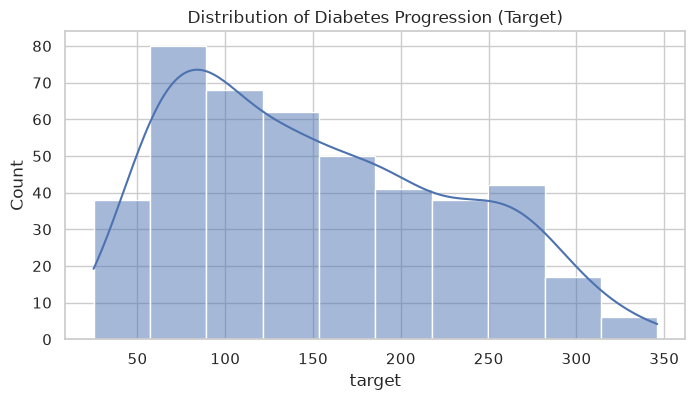


Correlation with Target Variable:
target    1.000000
bmi       0.586450
s5        0.565883
bp        0.441482
s4        0.430453
s6        0.382483
s1        0.212022
age       0.187889
s2        0.174054
sex       0.043062
s3       -0.394789
Name: target, dtype: float64


In [3]:
# Estadísticas resumidas e información
print("Data Types and Missing Values:")
display(df.info())

print("\nSummary Statistics:")
display(df.describe())

# Comprobar duplicados
print(f"\nDuplicate rows found: {df.duplicated().sum()}")

# Visualizar la Distribución del Objetivo
plt.figure(figsize=(8, 4))
sns.histplot(df['target'], kde=True)
plt.title("Distribution of Diabetes Progression (Target)")
plt.show()

# Correlación con la Variable Objetivo
correlations = df.corr()['target'].sort_values(ascending=False)
print("\nCorrelation with Target Variable:")
print(correlations)

## 5. Lógica de Extracción de Datos

En este cuaderno cargamos los datos directamente desde `sklearn`. Sin embargo, en una configuración de MLOps de producción, esta lógica se trasladará a un **script de Extracción de Datos** que podría obtener los datos de una base de datos SQL, un bucket en la nube (S3/GCS) o una API externa.

## 6. Comprobaciones de Validación de Datos

Antes del entrenamiento, verificamos que los datos cumplen nuestras expectativas. Estas comprobaciones eventualmente darán forma a un **script de Validación**.

In [4]:
def validate_data(dataframe):
    # 1. Comprobar si existe la columna objetivo
    assert 'target' in dataframe.columns, "Target column missing!"

    # 2. Comprobar si faltan las características requeridas
    required_features = ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
    for col in required_features:
        assert col in dataframe.columns, f"Feature {col} is missing!"

    # 3. Asegurar que todas las columnas son numéricas
    assert dataframe.select_dtypes(include=[np.number]).shape[1] == dataframe.shape[1], "Non-numeric data detected!"

    # 4. Valores Faltantes Críticos
    assert dataframe.isnull().sum().sum() == 0, "Critical missing values found!"

    # 5. Tamaño del Conjunto de Datos
    assert len(dataframe) > 0, "Dataset is empty!"

    print("✅ Data Validation Passed!")

validate_data(df)

✅ Data Validation Passed!


## 7. Limpieza de Datos

Aunque el conjunto de datos de Scikit-learn está limpio, demostramos el flujo de trabajo de limpieza que se automatizará en el proyecto final.

In [5]:
def clean_data(input_df):
    # Crear una copia para evitar efectos secundarios
    cleaned_df = input_df.copy()

    # Tratar los valores faltantes (demostración)
    cleaned_df = cleaned_df.dropna()

    # Eliminar duplicados
    cleaned_df = cleaned_df.drop_duplicates()

    # Asegurar que los tipos son correctos
    for col in cleaned_df.columns:
        cleaned_df[col] = pd.to_numeric(cleaned_df[col])

    return cleaned_df

print(f"Shape before cleaning: {df.shape}")
df_cleaned = clean_data(df)
print(f"Shape after cleaning: {df_cleaned.shape}")

Shape before cleaning: (442, 11)
Shape after cleaning: (442, 11)


## 8. Separación de Características y Objetivo

Separamos las características de entrada (X) del valor objetivo de progresión (y).

In [6]:
X = df_cleaned.drop(columns=['target'])
y = df_cleaned['target']

print("X represents our patient features.")
print("y represents the progression measure.")

X represents our patient features.
y represents the progression measure.


## 9. División en Entrenamiento y Prueba

Dividimos los datos para evaluar el modelo con datos no vistos.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training samples: {len(X_train)}")
print(f"Test samples: {len(X_test)}")

Training samples: 353
Test samples: 89


## 10. Entrenamiento del Modelo Base

Comparamos tres algoritmos de regresión simples.

In [8]:
models = {
    "LinearRegression": LinearRegression(),
    "RandomForest": RandomForestRegressor(n_estimators=100, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(random_state=42)
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)

    results.append({"Model": name, "RMSE": rmse, "MAE": mae, "R2": r2})

results_df = pd.DataFrame(results)
display(results_df)

,Model,RMSE,MAE,R2
0,LinearRegression,53.853446,42.794095,0.452603
1,RandomForest,54.332408,44.053034,0.442823
2,GradientBoosting,53.732952,44.529637,0.455050


## 11. Resultados de la Evaluación del Modelo

Identificamos el mejor modelo en función del Error Cuadrático Medio (RMSE).

In [9]:
best_model_row = results_df.loc[results_df['RMSE'].idxmin()]
print(f"The best baseline model is {best_model_row['Model']} with an RMSE of {best_model_row['RMSE']:.2f}")

The best baseline model is GradientBoosting with an RMSE of 53.73


## 12. Exploración Simple de Ingeniería de Características

Veamos si la creación de términos de interacción entre características mejora nuestros resultados.

In [10]:
df_eng = df_cleaned.copy()

# 1. Interacción entre IMC y edad
df_eng['bmi_age_interaction'] = df_eng['bmi'] * df_eng['age']

# 2. Interacción entre presión arterial y IMC
df_eng['bp_bmi_interaction'] = df_eng['bp'] * df_eng['bmi']

# 3. Ratio de las mediciones séricas (comprobando división por cero)
df_eng['s1_s2_ratio'] = df_eng['s1'] / (df_eng['s2'] + 1e-9)

# Dividir y entrenar de nuevo
X_eng = df_eng.drop(columns=['target'])
y_eng = df_eng['target']
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(X_eng, y_eng, test_size=0.2, random_state=42)

eng_results = []
for name, model in models.items():
    model.fit(X_train_e, y_train_e)
    preds = model.predict(X_test_e)
    rmse = np.sqrt(mean_squared_error(y_test_e, preds))
    eng_results.append({"Model": name + "_Eng", "RMSE": rmse})

display(pd.DataFrame(eng_results))

,Model,RMSE
0,LinearRegression_Eng,52.465151
1,RandomForest_Eng,55.399354
2,GradientBoosting_Eng,56.118532


## 13. Conclusión Final de la Ciencia de Datos

### Hallazgos
- **Mejor modelo base:** **GradientBoosting** logró el RMSE de prueba más bajo (**53.73**), por delante de LinearRegression (**53.85**) y RandomForest (**54.33**).
- **Ingeniería de Características:** el modelo lineal mejorado alcanzó un RMSE de **52.47**, pero los modelos de árbol empeoraron. Las características de interacción no se promovieron a la API de producción porque la mejora fue pequeña y complicaría el contrato de servicio.
- **Métricas:** se priorizó el RMSE para penalizar los errores mayores; el MAE y el R² se monitorearon para garantizar la consistencia.
- **Preparación:** los datos están limpios, pero requieren un paso de validación estructurado para garantizar la consistencia cuando lleguen nuevos datos.

### Próximos Pasos en la MLOps
El trabajo exploratorio está completo. El siguiente paso es convertir este cuaderno en un repositorio MLOps **estructurado** y listo para producción, que incluye:
- `requirements.txt` para la gestión de dependencias.
- La configuración de un entorno virtual local.
- Módulos de **extracción, validación y limpieza de datos**.
- **train.py** para el entrenamiento del modelo con el seguimiento de MLflow.
- **Model Registry** y selección del campeón con una puerta de calidad.
- **FastAPI** para servir al campeón a través de `/health`, `/model-info` y `/predict`.
- **GitHub Actions** para automatizar el pipeline y los tests.
- **README.md** que documenta todo el ciclo de vida del proyecto.

## 14. Entrega a Producción (Repositorio MLOps)

El flujo de trabajo exploratorio de este cuaderno está implementado en el paquete reutilizable bajo `mlops/`:

- `mlops/data/` — extracción, validación, limpieza y división determinista de entrenamiento/prueba.
- `mlops/training/` — entrenamiento de candidatos con seguimiento de MLflow, registro y selección del campeón.
- `mlops/api/` — servicio FastAPI que carga el alias `champion` del MLflow Model Registry.
- `mlops/pipeline.py` — orquesta `extract -> validate -> clean -> split -> train -> register`.

El pipeline de producción utiliza la misma división determinista (`random_state=42`, `test_size=0.2`) y los mismos candidatos base que este cuaderno, envueltos en pipelines de scikit-learn. Selecciona el modelo por el RMSE de prueba y lo promueve solo cuando el RMSE es **<= 60.0**.

El primer campeón registrado fue **GradientBoosting**, con un RMSE de prueba de **53.73**, un MAE de **44.53** y un R² de **0.455**, superando cómodamente la puerta de calidad. El artefacto se sirve a través del alias `champion`, por lo que promover una versión futura no requiere reiniciar la definición de la API.

Este cuaderno sigue siendo el artefacto exploratorio; el repositorio contiene la implementación reproducible y probada.